# What does an account look like on its own?

I group accounts by how many hands they played. This helps put a long session or a low house win rate in context before looking for coordination.

In [1]:
from pathlib import Path

import duckdb

database = Path("../private/wagers.duckdb")
con = duckdb.connect(str(database), read_only=True, config={"threads": 4, "memory_limit": "3GB"})

In [2]:
groups = con.sql('''
    WITH accounts AS (
        SELECT member, count(*) AS hands, count(DISTINCT date) AS active_days,
               sum(bet) AS turnover, sum(wl) AS house_win, sum(theo) AS expected_win
        FROM wagers
        WHERE member IS NOT NULL
        GROUP BY member
    ), bands AS (
        SELECT *, CASE
            WHEN hands < 100 THEN 1
            WHEN hands < 1000 THEN 2
            WHEN hands < 5000 THEN 3
            WHEN hands < 20000 THEN 4
            ELSE 5 END AS band
        FROM accounts
    )
    SELECT band, count(*) AS accounts, sum(hands)::BIGINT AS hands,
           median(active_days) AS median_active_days,
           round(100 * sum(house_win) / nullif(sum(turnover), 0), 2) AS actual_pct,
           round(100 * sum(expected_win) / nullif(sum(turnover), 0), 2) AS expected_pct
    FROM bands GROUP BY band ORDER BY band
''').df()
groups["hands per account"] = ["<100", "100–999", "1,000–4,999", "5,000–19,999", "20,000+"]
display(groups.drop(columns="band"))

,accounts,hands,median_active_days,actual_pct,expected_pct,hands per account
0,68525,1107962,1.0,7.53,2.14,<100
1,15983,5682504,9.0,2.93,2.09,100–999
2,6885,15740675,31.0,1.50,2.02,"1,000–4,999"
3,2218,19930214,54.0,1.46,1.78,"5,000–19,999"
4,206,5982352,72.0,1.66,1.64,"20,000+"


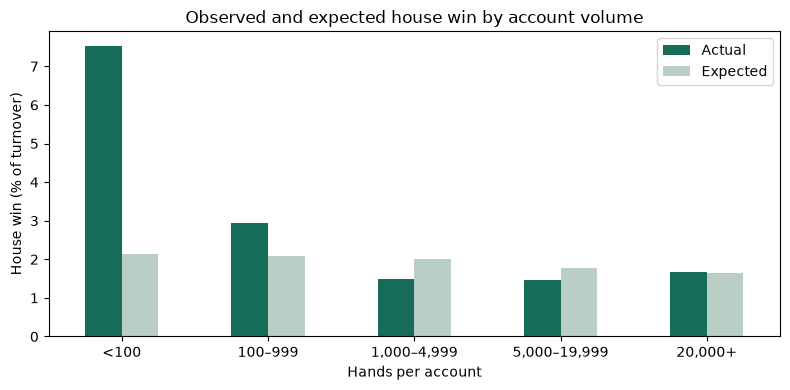

In [3]:
%matplotlib inline
import matplotlib.pyplot as plt

plot_data = groups.set_index("hands per account")[["actual_pct", "expected_pct"]]
plot_data.columns = ["Actual", "Expected"]
ax = plot_data.plot.bar(color=["#176c59", "#b9cec7"], rot=0, figsize=(8, 4))
ax.set(xlabel="Hands per account", ylabel="House win (% of turnover)",
       title="Observed and expected house win by account volume")
ax.get_figure().tight_layout()
plt.show()
con.close()

Small-volume accounts have the largest gap between observed and expected house win in this view. These are turnover-weighted group rates. They tell me little about whether two accounts acted together, so the next notebook uses repeated co-play.